# 05.02 — Non-HRV variable inspection

**Stage:** `data_inspection` · **Notebook 2 of 3**  
**Scope:** descriptive inspection of **continuous non-HRV variables** in the final analytical cohort.  
**Input:** `outputs/dataset_final.csv` (current release: 402 source records).  
**Outputs:** descriptive CSVs, **informative multipanel figures**, `README_05_non_hrv_inspection.md`, and `05_non_hrv_inspection_results.md`.

## Analytical boundaries

- Inspect **age**, **body weight**, **height**, **BMI**, **systolic and diastolic BP**, **mean arterial pressure (MAP/PAM)**, and **pulse pressure (PP)**.
- Examine distributions, descriptive tails, Q–Q visual diagnostics, and **non-inferential relationships among continuous non-HRV measures**.
- `height_m` is retained in the source and checked as an alternative unit representation of `height_cm`. Only centimeters are plotted, avoiding two panels of the same height measurement.
- `sex`, `age_group`, `sex_category`, `sbp_category`, `dbp_category`, `bmi_category` and `bmi_reference` are **not analyzed here**. Their frequencies, category counts, and category combinations belong exclusively to notebook **05.03**.
- No HRV outcomes, HRV-vs-factor comparisons, inference, predictive models, clustering, transformations of input data, or exclusion of outliers.
- **A data-distribution difference is not evidence that a source value is wrong.** Descriptive tail flags and redundancy checks do not change the cohort.
- **Multipanel principle:** export views grouped by purpose, not separate PNG files for every variable and plot type.

Suggested location: `notebooks/data_inspection/05_02_non_hrv_inspection.ipynb`. The project root is located by searching for `outputs/dataset_final.csv` in the execution directory or its parents. Set `INPUT_FILE_OVERRIDE` only when necessary.

## 1. Configuration, input, and structural validation

This notebook reads the **final 402-record cohort** produced by preprocessing. The documented release size is informational; if a future version has a different size, it will be reported without silently filtering rows. Continuous variables are inspected at their source scale and in their original units.

In [1]:
from pathlib import Path
from itertools import combinations
from hashlib import sha256
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Image

EXPECTED_N = 402  # Documented preprocessing release, not an exclusion rule.
INPUT_FILE_OVERRIDE = None  # Example: Path('/absolute/path/dataset_final.csv')
SAVE_DPI = 150
SHOW_MULTIPANELS_IN_NOTEBOOK = True
MAKE_QQ_PANEL = True
MAKE_PAIR_GRIDS = True
MAKE_CROSS_DOMAIN_PANEL = True
REPLACE_PREVIOUS_GENERATED_FIGURES = True  # Only files referenced in the previous manifest.

VARIABLE_INFO = {
    'age': ('Age', 'Demography', 'years'),
    'weight_kg': ('Weight', 'Anthropometry', 'kg'),
    'height_cm': ('Height', 'Anthropometry', 'cm'),
    'imc': ('BMI', 'Anthropometry', 'kg/m²'),
    'bp_systolic': ('SBP', 'Blood pressure', 'mmHg'),
    'bp_diastolic': ('DBP', 'Blood pressure', 'mmHg'),
    'bp_pam': ('MAP / PAM', 'Blood pressure', 'mmHg'),
    'bp_pp': ('Pulse pressure', 'Blood pressure', 'mmHg'),
}
ALL_COLS = list(VARIABLE_INFO)
DEMO_ANTHRO_COLS = ['age', 'weight_kg', 'height_cm', 'imc']
BP_COLS = ['bp_systolic', 'bp_diastolic', 'bp_pam', 'bp_pp']
SOURCE_COLUMN = 'source_excel_row'
HEIGHT_ALTERNATIVE = 'height_m'


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'outputs' / 'dataset_final.csv').is_file():
            return candidate
    raise FileNotFoundError(
        'Cannot find outputs/dataset_final.csv from the working directory. '
        'Set INPUT_FILE_OVERRIDE or execute from within the project tree.'
    )

if INPUT_FILE_OVERRIDE is None:
    PROJECT_ROOT = find_project_root(Path.cwd().resolve())
    INPUT_FILE = PROJECT_ROOT / 'outputs' / 'dataset_final.csv'
else:
    INPUT_FILE = Path(INPUT_FILE_OVERRIDE).expanduser().resolve()
    if not INPUT_FILE.is_file():
        raise FileNotFoundError(f'Missing input file: {INPUT_FILE}')
    PROJECT_ROOT = INPUT_FILE.parent.parent

OUTPUT_DIR = PROJECT_ROOT / 'eda_results' / 'data_inspection' / '05_02_non_hrv_inspection'
TABLES_DIR = OUTPUT_DIR / 'tables'
MULTIPANEL_DIR = OUTPUT_DIR / 'figures' / 'multipanels'
for directory in (TABLES_DIR, MULTIPANEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

source_df = pd.read_csv(INPUT_FILE)
required = [SOURCE_COLUMN, *ALL_COLS, HEIGHT_ALTERNATIVE]
missing_columns = [column for column in required if column not in source_df.columns]
if missing_columns:
    raise ValueError(f'Missing required columns: {missing_columns}')
if source_df[SOURCE_COLUMN].isna().any() or source_df[SOURCE_COLUMN].duplicated().any():
    raise ValueError('source_excel_row must contain unique nonmissing provenance identifiers.')
for column in (*ALL_COLS, HEIGHT_ALTERNATIVE):
    if not pd.api.types.is_numeric_dtype(source_df[column]):
        raise TypeError(f'Column is not numeric: {column}; inspect preprocessing rather than silently coercing.')
    observed = source_df[column].dropna().to_numpy(dtype=float)
    if not np.isfinite(observed).all():
        raise ValueError(f'Nonfinite numerical observations in {column}.')

N_RECORDS = len(source_df)
if N_RECORDS == 0:
    raise ValueError('Empty analytical cohort.')
if N_RECORDS != EXPECTED_N:
    print(f'NOTE: {N_RECORDS} records observed; documentation reference: {EXPECTED_N}. No rows removed.')
else:
    print(f'Input verified: {N_RECORDS} records, {len(ALL_COLS)} plotted continuous variables.')

sns.set_theme(style='whitegrid', context='notebook', palette='deep')
plt.rcParams.update({
    'figure.dpi': 100, 'savefig.dpi': SAVE_DPI,
    'axes.titlesize': 10.5, 'axes.titleweight': 'semibold',
    'axes.labelsize': 9.5, 'font.size': 9.5,
})

# Protect unlisted files. On re-runs, remove only previously generated PNGs
# explicitly recorded in this notebook's prior figure manifest.
old_manifest_path = TABLES_DIR / 'figure_manifest.csv'
if REPLACE_PREVIOUS_GENERATED_FIGURES and old_manifest_path.is_file():
    old_manifest = pd.read_csv(old_manifest_path)
    for entry in old_manifest.get('figure', pd.Series(dtype=str)).dropna():
        old_file = (OUTPUT_DIR / str(entry)).resolve()
        if (old_file.is_relative_to(MULTIPANEL_DIR.resolve())
                and old_file.is_file() and old_file.suffix.lower() == '.png'):
            old_file.unlink()

INPUT_SHA256 = sha256(INPUT_FILE.read_bytes()).hexdigest()
figure_records = []

def label(column):
    return VARIABLE_INFO[column][0]

def axis_label(column):
    return f'{label(column)} ({VARIABLE_INFO[column][2]})'

def save_figure(fig, filename, kind, description):
    path = MULTIPANEL_DIR / filename
    fig.savefig(path, dpi=SAVE_DPI, bbox_inches='tight', facecolor='white')
    figure_records.append({
        'figure': str(path.relative_to(OUTPUT_DIR)),
        'kind': kind,
        'description': description,
    })
    plt.close(fig)
    return path

def show_panel(path, width=1050):
    if SHOW_MULTIPANELS_IN_NOTEBOOK:
        display(Image(filename=str(path), width=width))

print('Input:', INPUT_FILE)
print('Outputs:', OUTPUT_DIR)
print('Measurements available per variable:')
display(source_df[[*ALL_COLS, HEIGHT_ALTERNATIVE]].count().rename('n_valid').to_frame())

Input verified: 402 records, 8 plotted continuous variables.
Input: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/outputs/dataset_final.csv
Outputs: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/eda_results/data_inspection/05_02_non_hrv_inspection
Measurements available per variable:


,n_valid
age,402
weight_kg,402
height_cm,402
imc,402
bp_systolic,402
bp_diastolic,402
bp_pam,402
bp_pp,402
height_m,402


## 2. Univariate descriptive statistics

The summary reports completeness, central tendency, dispersion, quantiles, coefficient of variation where meaningful, sample skewness and sample excess kurtosis. Tukey 1.5×IQR and 3×IQR limits are **only descriptive tail labels**, not evidence of recording errors or reasons to exclude observations. The alternative height column (`height_m`) is summarized separately to avoid counting the same measurement as two independent characteristics.

In [2]:
def summarize_numeric(column):
    values = source_df[column].dropna().astype(float)
    n = len(values)
    q = values.quantile([.01, .05, .25, .50, .75, .95, .99]) if n else pd.Series(dtype=float)
    q25 = float(q.get(.25, np.nan))
    q75 = float(q.get(.75, np.nan))
    iqr = q75 - q25
    lo15, hi15 = q25 - 1.5 * iqr, q75 + 1.5 * iqr
    lo30, hi30 = q25 - 3.0 * iqr, q75 + 3.0 * iqr
    mean = float(values.mean()) if n else np.nan
    sd = float(values.std(ddof=1)) if n > 1 else np.nan
    n15 = int(((values < lo15) | (values > hi15)).sum())
    n30 = int(((values < lo30) | (values > hi30)).sum())
    return {
        'variable': column, 'label': label(column) if column in VARIABLE_INFO else 'Height (m)',
        'domain': VARIABLE_INFO[column][1] if column in VARIABLE_INFO else 'Anthropometry (alternate unit)',
        'unit': VARIABLE_INFO[column][2] if column in VARIABLE_INFO else 'm',
        'n_total': N_RECORDS, 'n_valid': n,
        'n_missing': N_RECORDS - n,
        'missing_pct': 100 * (N_RECORDS - n) / N_RECORDS,
        'mean': mean, 'std': sd, 'median': q.get(.50, np.nan),
        'min': float(values.min()) if n else np.nan,
        'p01': q.get(.01, np.nan), 'p05': q.get(.05, np.nan),
        'q25': q25, 'q75': q75,
        'p95': q.get(.95, np.nan), 'p99': q.get(.99, np.nan),
        'max': float(values.max()) if n else np.nan,
        'iqr': iqr,
        'cv_pct': 100 * sd / abs(mean) if n > 1 and not np.isclose(mean, 0) else np.nan,
        'skewness': values.skew() if n > 2 else np.nan,
        'excess_kurtosis': values.kurt() if n > 3 else np.nan,
        'n_outside_1_5_iqr': n15, 'pct_outside_1_5_iqr': 100 * n15 / n if n else np.nan,
        'n_outside_3_iqr': n30, 'pct_outside_3_iqr': 100 * n30 / n if n else np.nan,
        'lower_1_5_iqr': lo15, 'upper_1_5_iqr': hi15,
        'lower_3_iqr': lo30, 'upper_3_iqr': hi30,
    }

summary = pd.DataFrame([summarize_numeric(c) for c in ALL_COLS])
alternative_height_summary = pd.DataFrame([summarize_numeric(HEIGHT_ALTERNATIVE)])
summary.to_csv(TABLES_DIR / 'non_hrv_descriptive_statistics.csv', index=False)
alternative_height_summary.to_csv(TABLES_DIR / 'height_m_alternative_summary.csv', index=False)

tail_summary = summary[[
    'variable','label','n_valid','n_outside_1_5_iqr','pct_outside_1_5_iqr',
    'n_outside_3_iqr','pct_outside_3_iqr','lower_1_5_iqr','upper_1_5_iqr',
    'lower_3_iqr','upper_3_iqr',
]].copy()
tail_summary.to_csv(TABLES_DIR / 'non_hrv_tukey_tail_summary.csv', index=False)

display(summary[[
    'label','n_valid','n_missing','mean','median','std','q25','q75','min','max','skewness',
    'n_outside_1_5_iqr',
]].round(3))
print('Tukey fences count descriptive tails; no value is deleted or modified.')

,label,n_valid,n_missing,mean,median,std,q25,q75,min,max,skewness,n_outside_1_5_iqr
0,Age,402,0,70.851,70.000,5.889,66.000,75.000,60.000,89.000,0.580,1
1,Weight,402,0,75.798,74.250,14.670,65.125,84.750,47.000,120.000,0.734,8
2,Height,402,0,156.433,156.000,8.896,150.000,161.000,130.000,180.000,0.115,8
3,BMI,402,0,31.027,30.012,5.747,26.803,34.001,18.359,57.075,0.762,7
4,SBP,402,0,130.575,129.000,16.697,120.000,140.000,80.000,176.000,0.244,6
5,DBP,402,0,77.687,77.000,10.259,71.000,84.000,52.000,115.000,0.242,5
6,MAP / PAM,402,0,95.316,94.333,11.010,88.333,102.000,66.000,129.667,0.272,5
7,Pulse pressure,402,0,52.888,51.000,13.727,43.000,61.000,16.000,100.000,0.307,3


Tukey fences count descriptive tails; no value is deleted or modified.


## 3. Multipanel distribution profiles at the original scale

Two consolidated sheets, each organized into rows by variable and columns by view: **histogram/KDE**, **violin/quartile plot**, and **ECDF**. The first covers age and anthropometry; the second covers blood pressure. These are descriptive views in native measurement units, without categories, group comparisons, or modeling.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.
findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


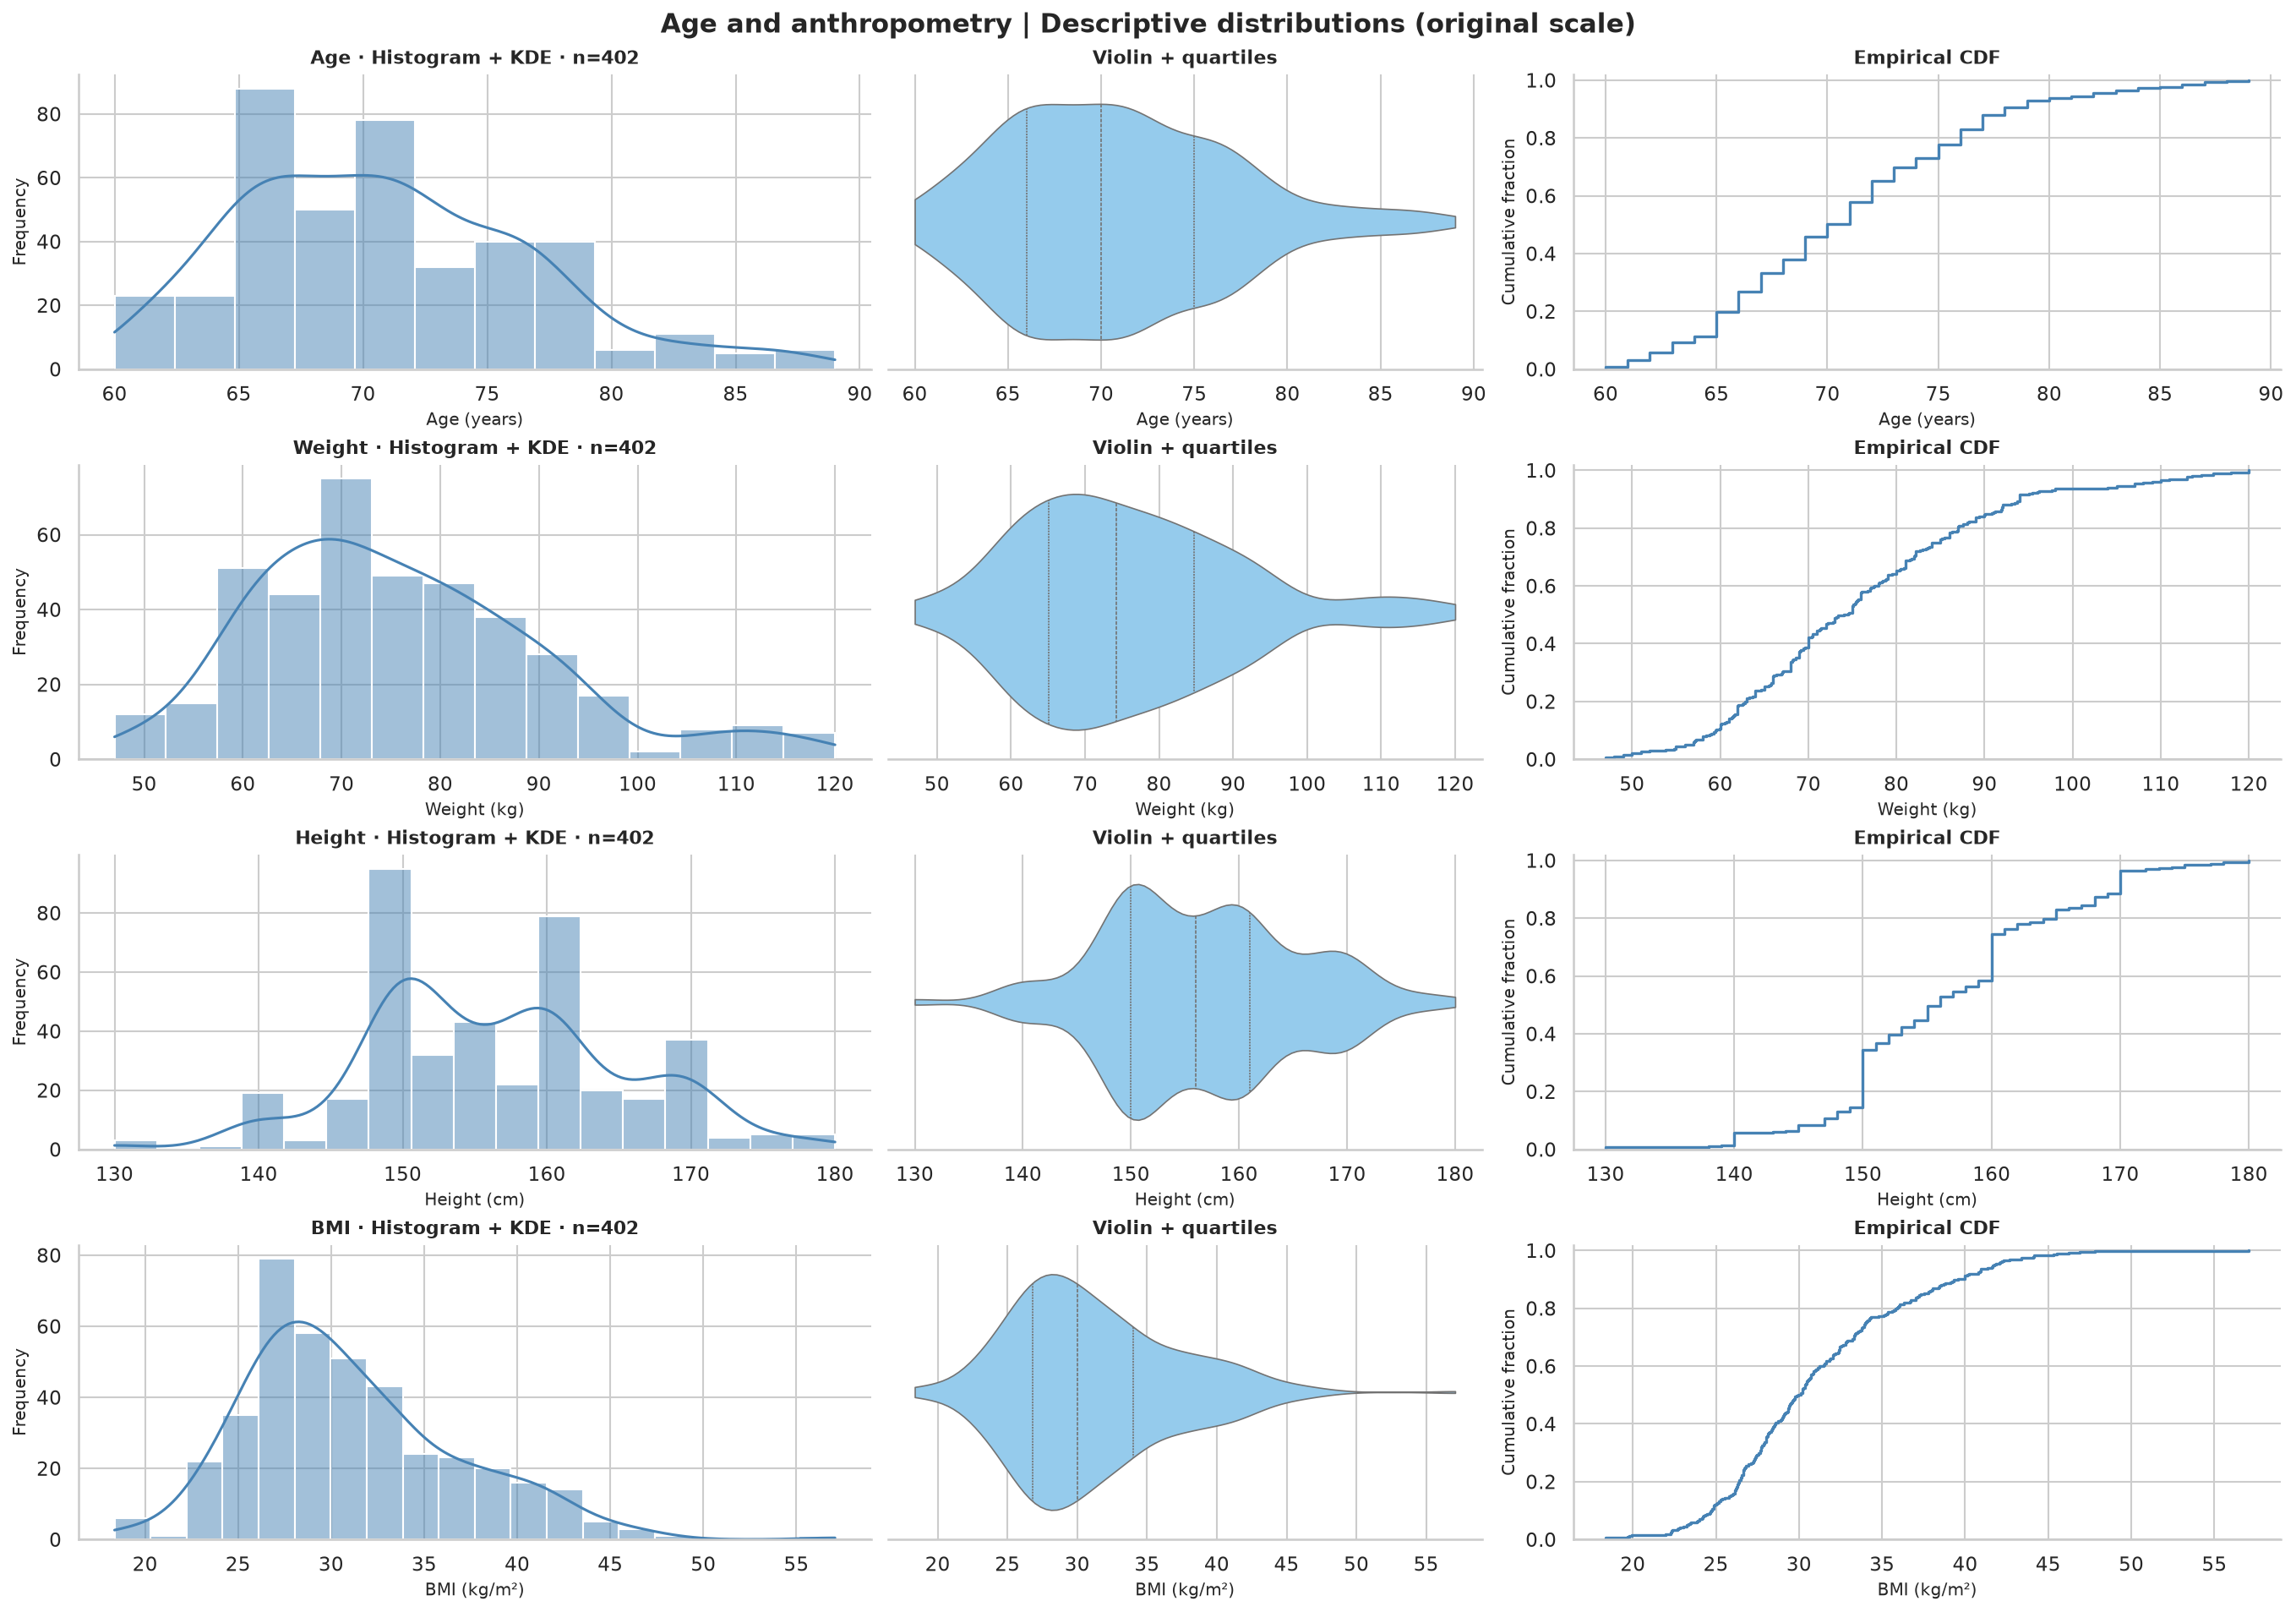

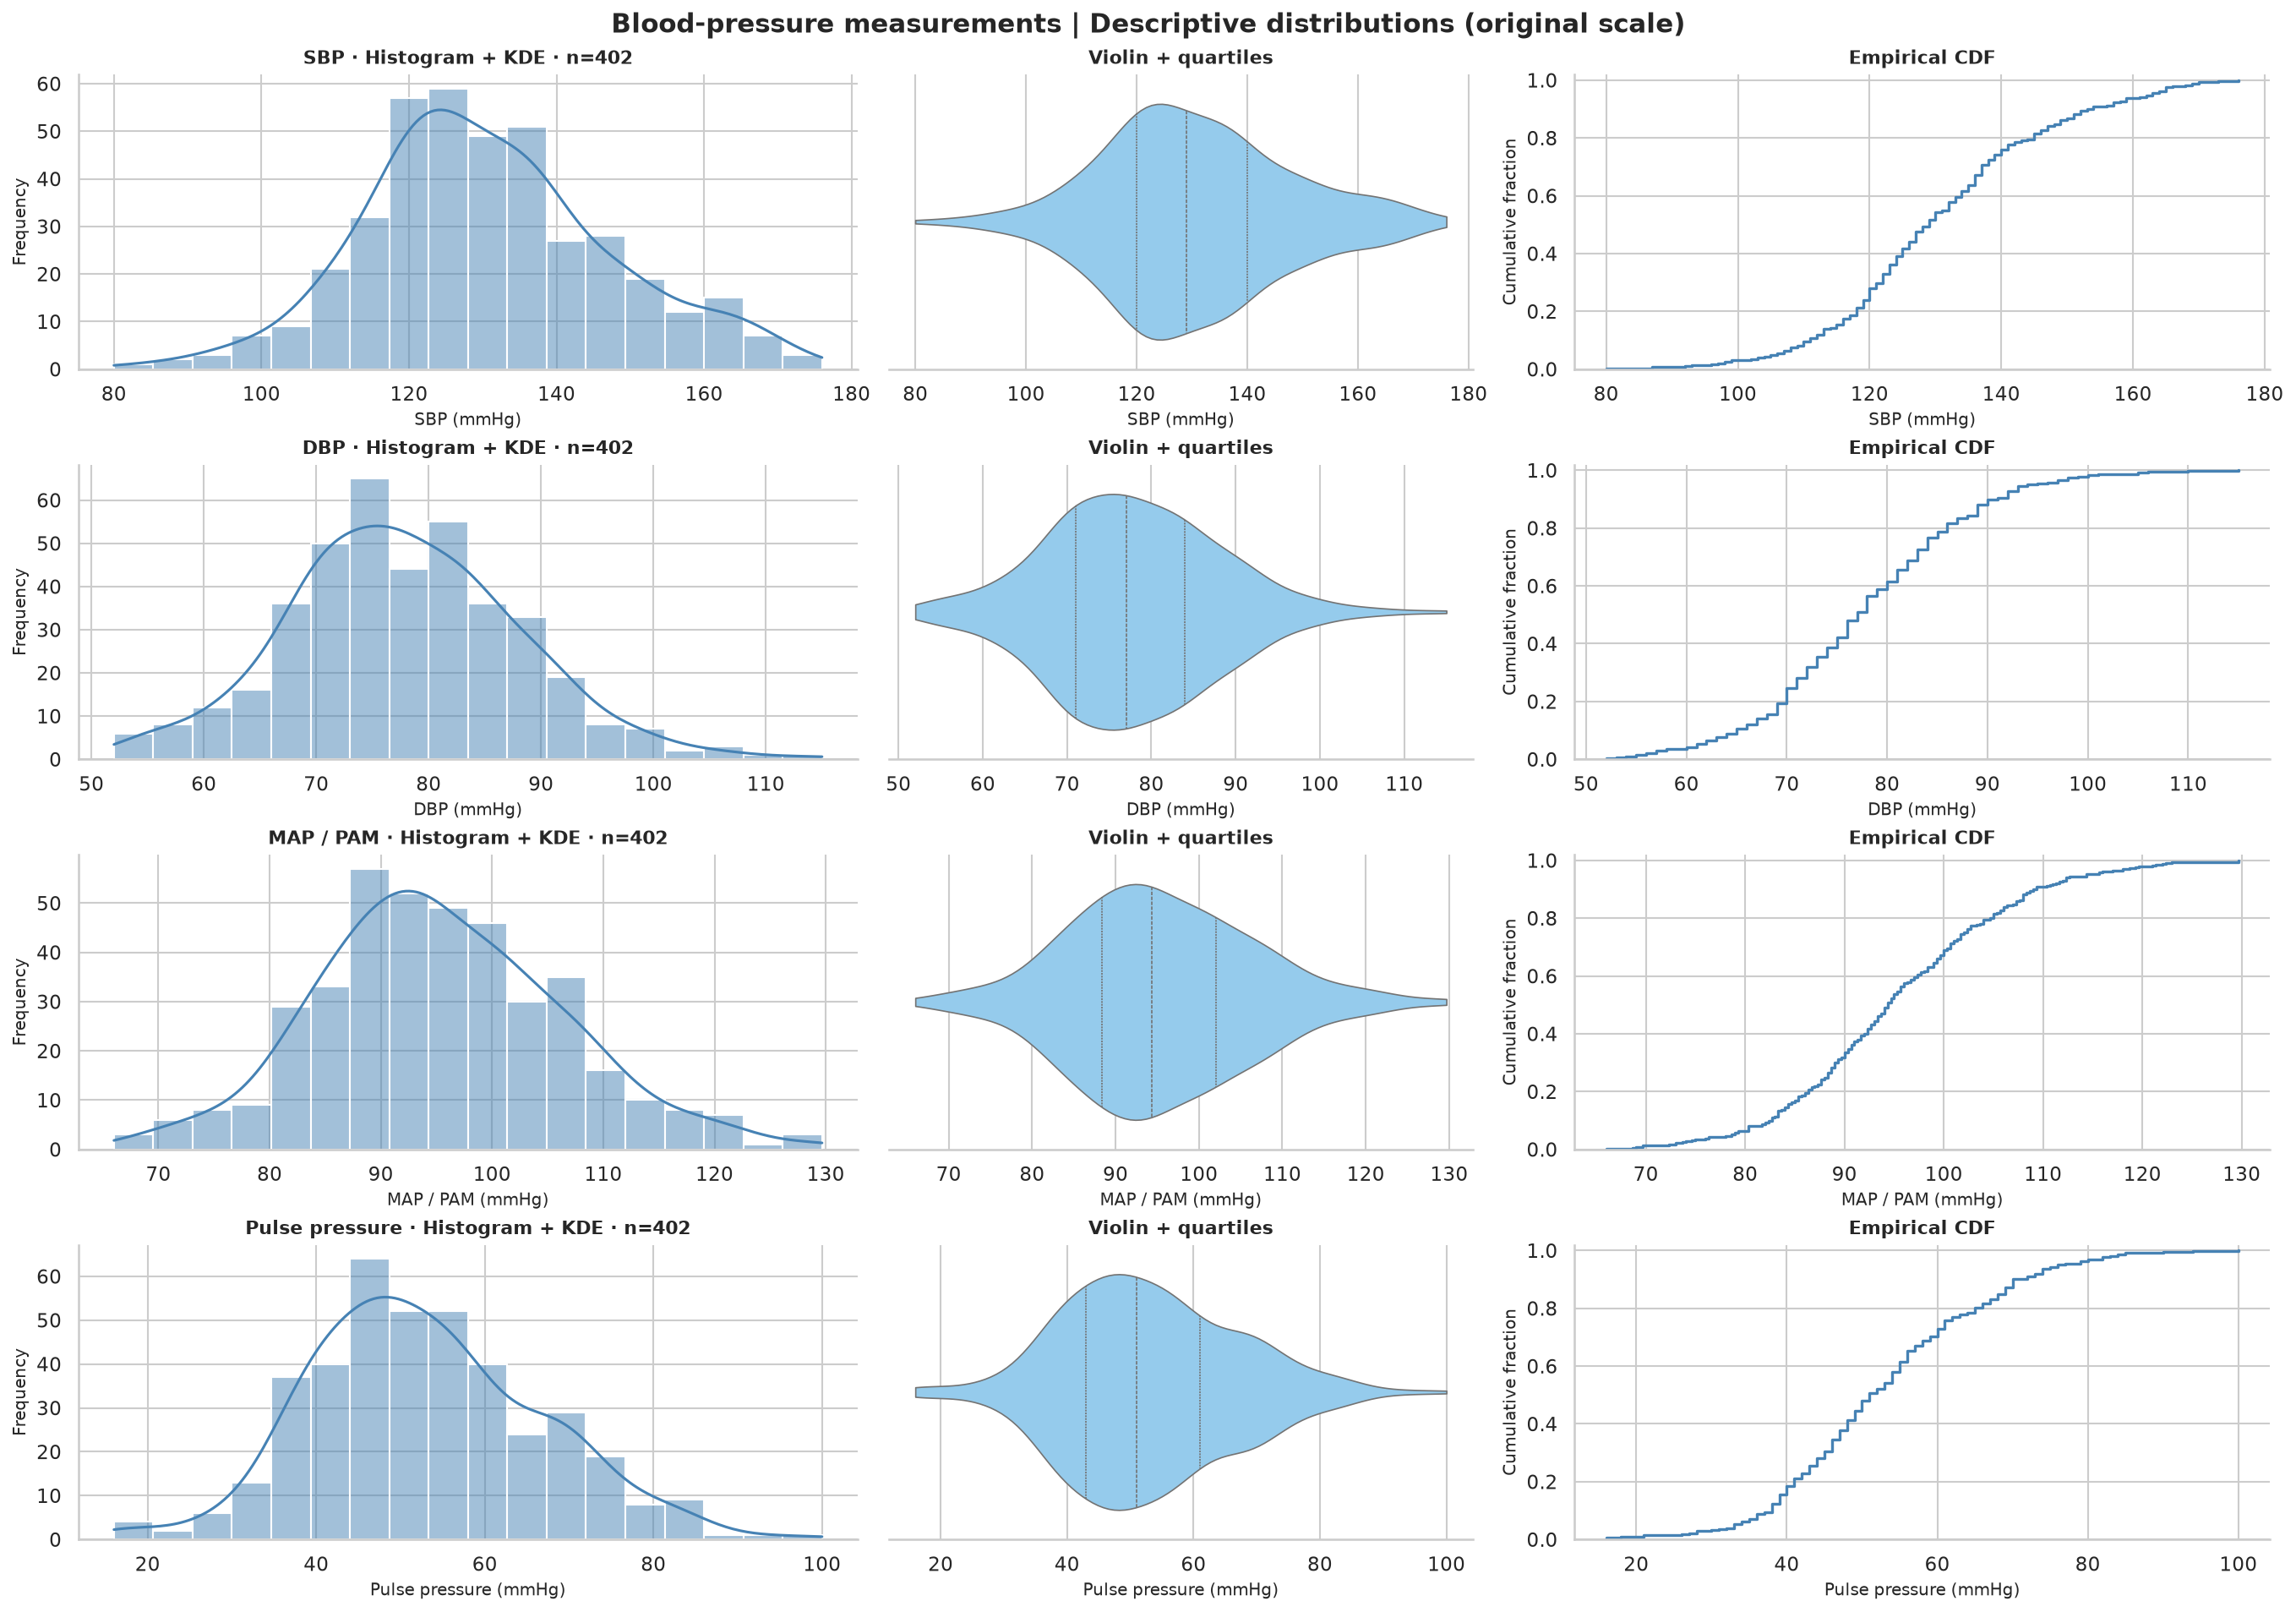

In [3]:
def distribution_profile_panel(columns, filename, title):
    fig, axes = plt.subplots(
        len(columns), 3,
        figsize=(18.0, 3.15 * len(columns)),
        gridspec_kw={'width_ratios': [1.4, 1.05, 1.25]},
        constrained_layout=True,
        squeeze=False,
    )
    for row_index, column in enumerate(columns):
        vals = source_df[column].dropna().astype(float)
        n = len(vals)
        ax_hist, ax_violin, ax_ecdf = axes[row_index]
        if n:
            sns.histplot(x=vals, bins='auto', kde=vals.nunique() > 2,
                         color='steelblue', ax=ax_hist)
            sns.violinplot(x=vals, inner='quart', cut=0, ax=ax_violin,
                           color='lightskyblue', linewidth=0.8)
            sns.ecdfplot(x=vals, ax=ax_ecdf, color='steelblue', linewidth=1.6)
        ax_hist.set(title=f'{label(column)} · Histogram + KDE · n={n}',
                    xlabel=axis_label(column), ylabel='Frequency')
        ax_violin.set(title='Violin + quartiles', xlabel=axis_label(column), ylabel='')
        ax_ecdf.set(title='Empirical CDF', xlabel=axis_label(column), ylabel='Cumulative fraction', ylim=(0, 1.02))
        sns.despine(ax=ax_hist)
        sns.despine(ax=ax_violin, left=True)
        sns.despine(ax=ax_ecdf)
    fig.suptitle(title, fontsize=15, fontweight='semibold')
    return save_figure(fig, filename, 'distribution_profiles',
                       f'{len(columns)} variables × 3 descriptive views (original units)')

p1 = distribution_profile_panel(
    DEMO_ANTHRO_COLS,
    '01_age_anthropometry_distribution_profiles.png',
    'Age and anthropometry | Descriptive distributions (original scale)',
)
show_panel(p1)

p2 = distribution_profile_panel(
    BP_COLS,
    '02_blood_pressure_distribution_profiles.png',
    'Blood-pressure measurements | Descriptive distributions (original scale)',
)
show_panel(p2)

## 4. Distribution diagnostics and descriptive tails

Normal Q–Q plots provide a **visual description of distribution shape**, not a requirement for using a given variable. The IQR panel shows tail observations relative to sample quantiles; it does **not** label clinical abnormalities or justify excluding measurements. No log transformations are imposed: age, weight, height, BMI, and pressure values remain in clinically familiar original units.

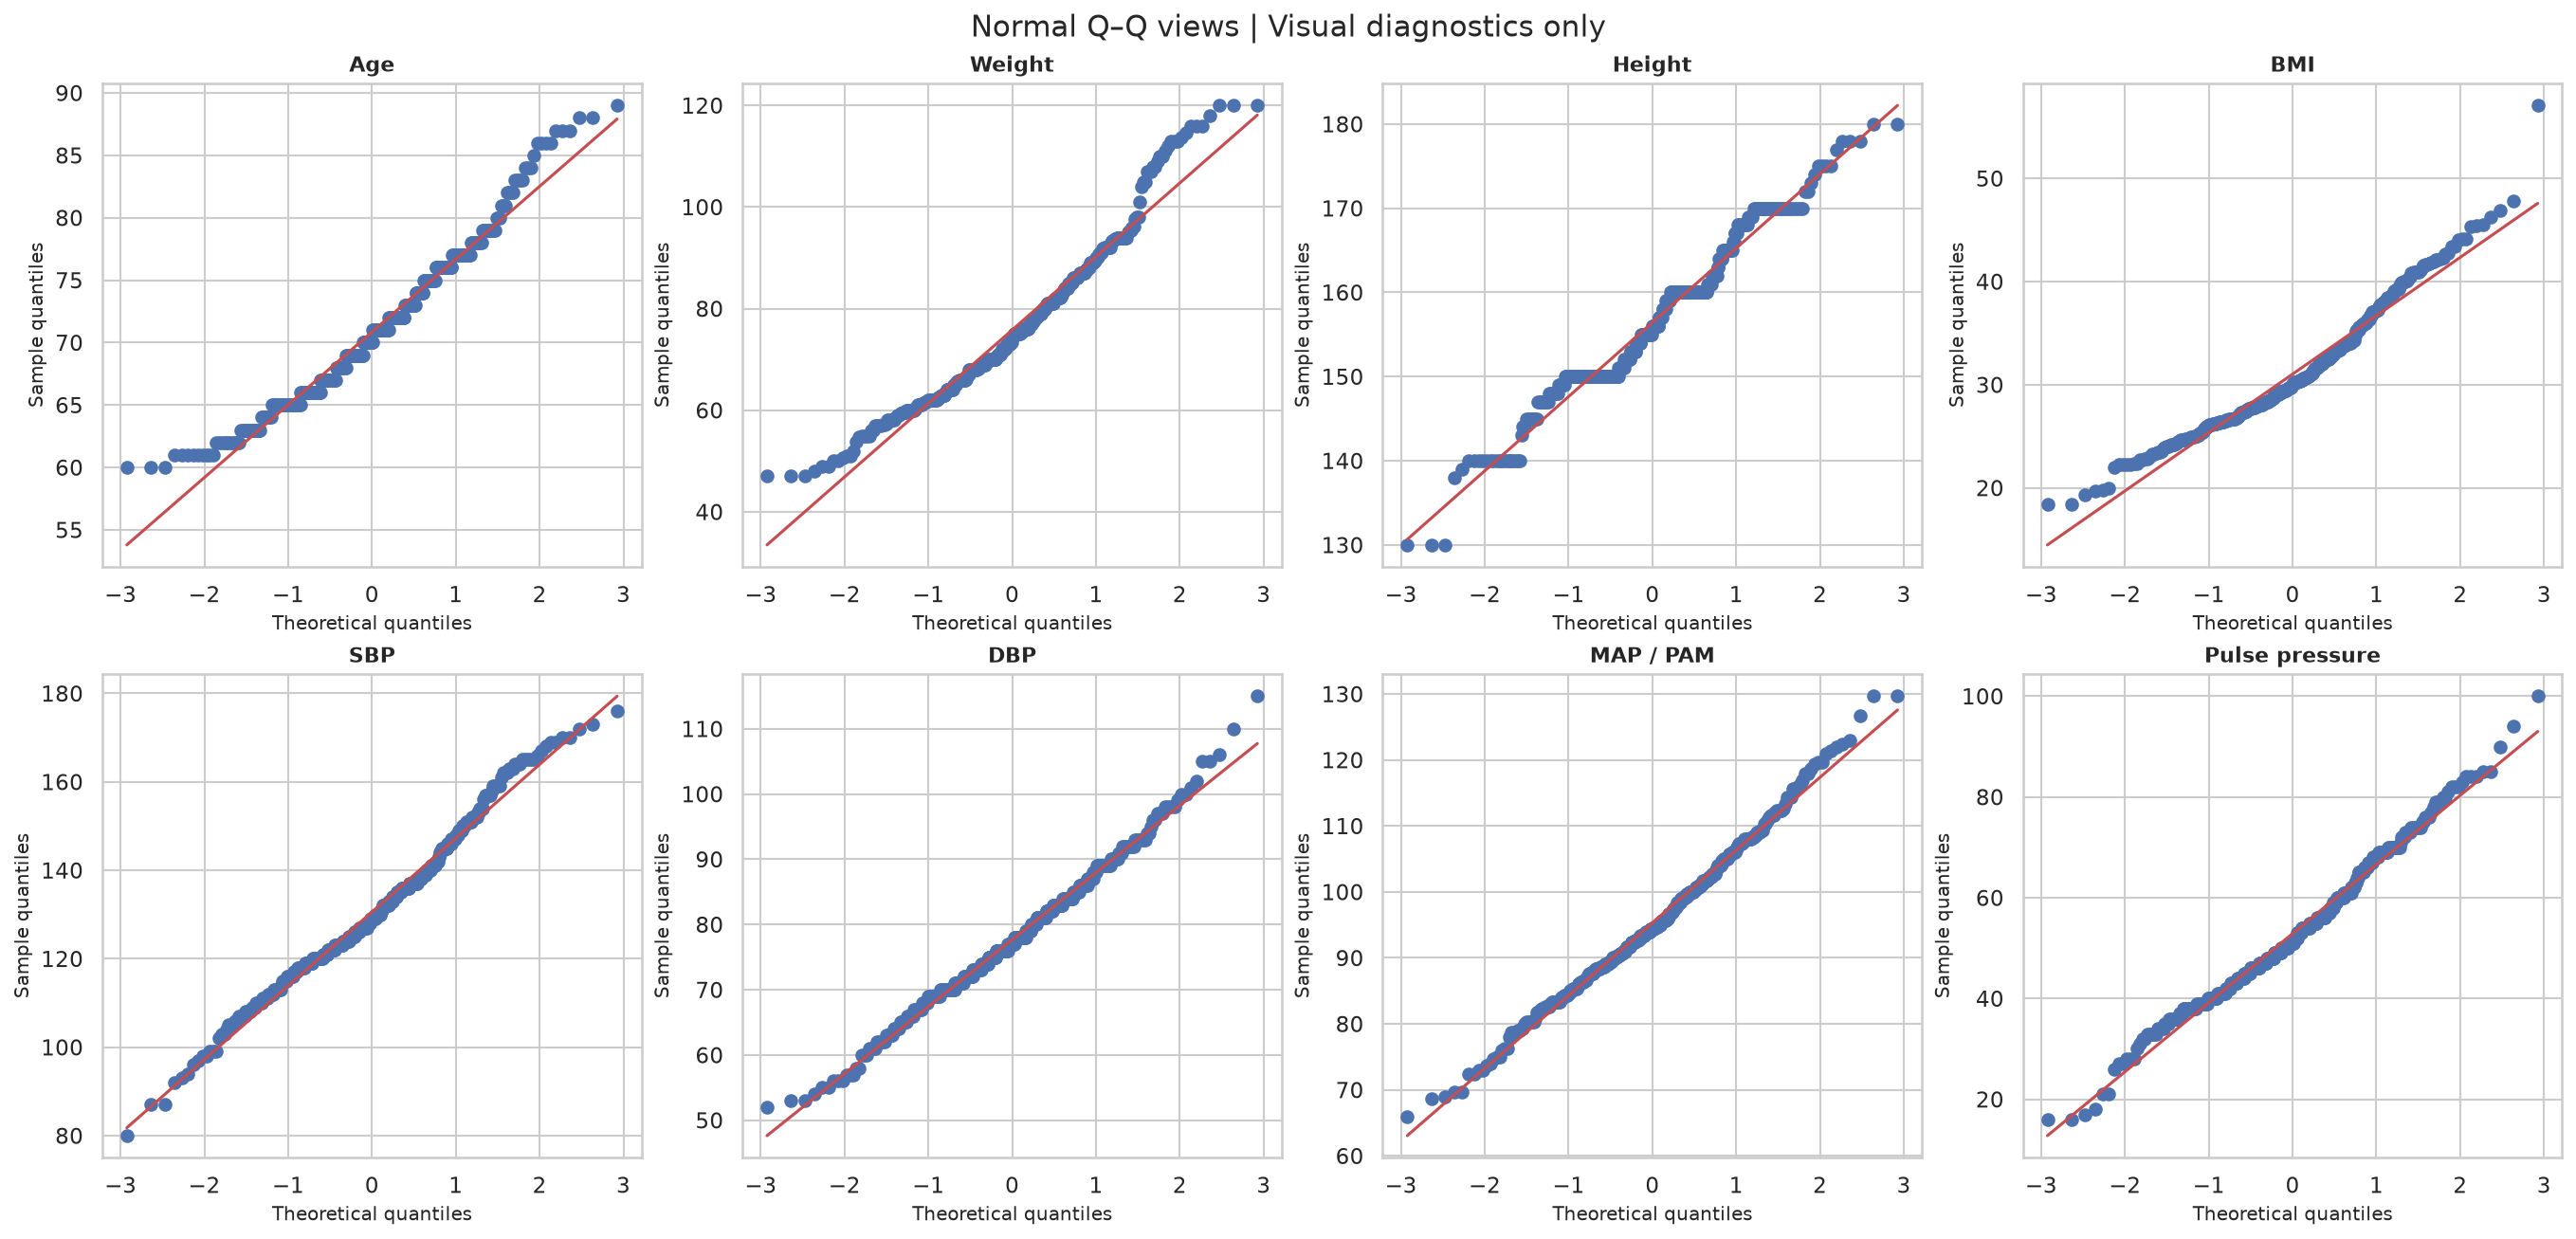

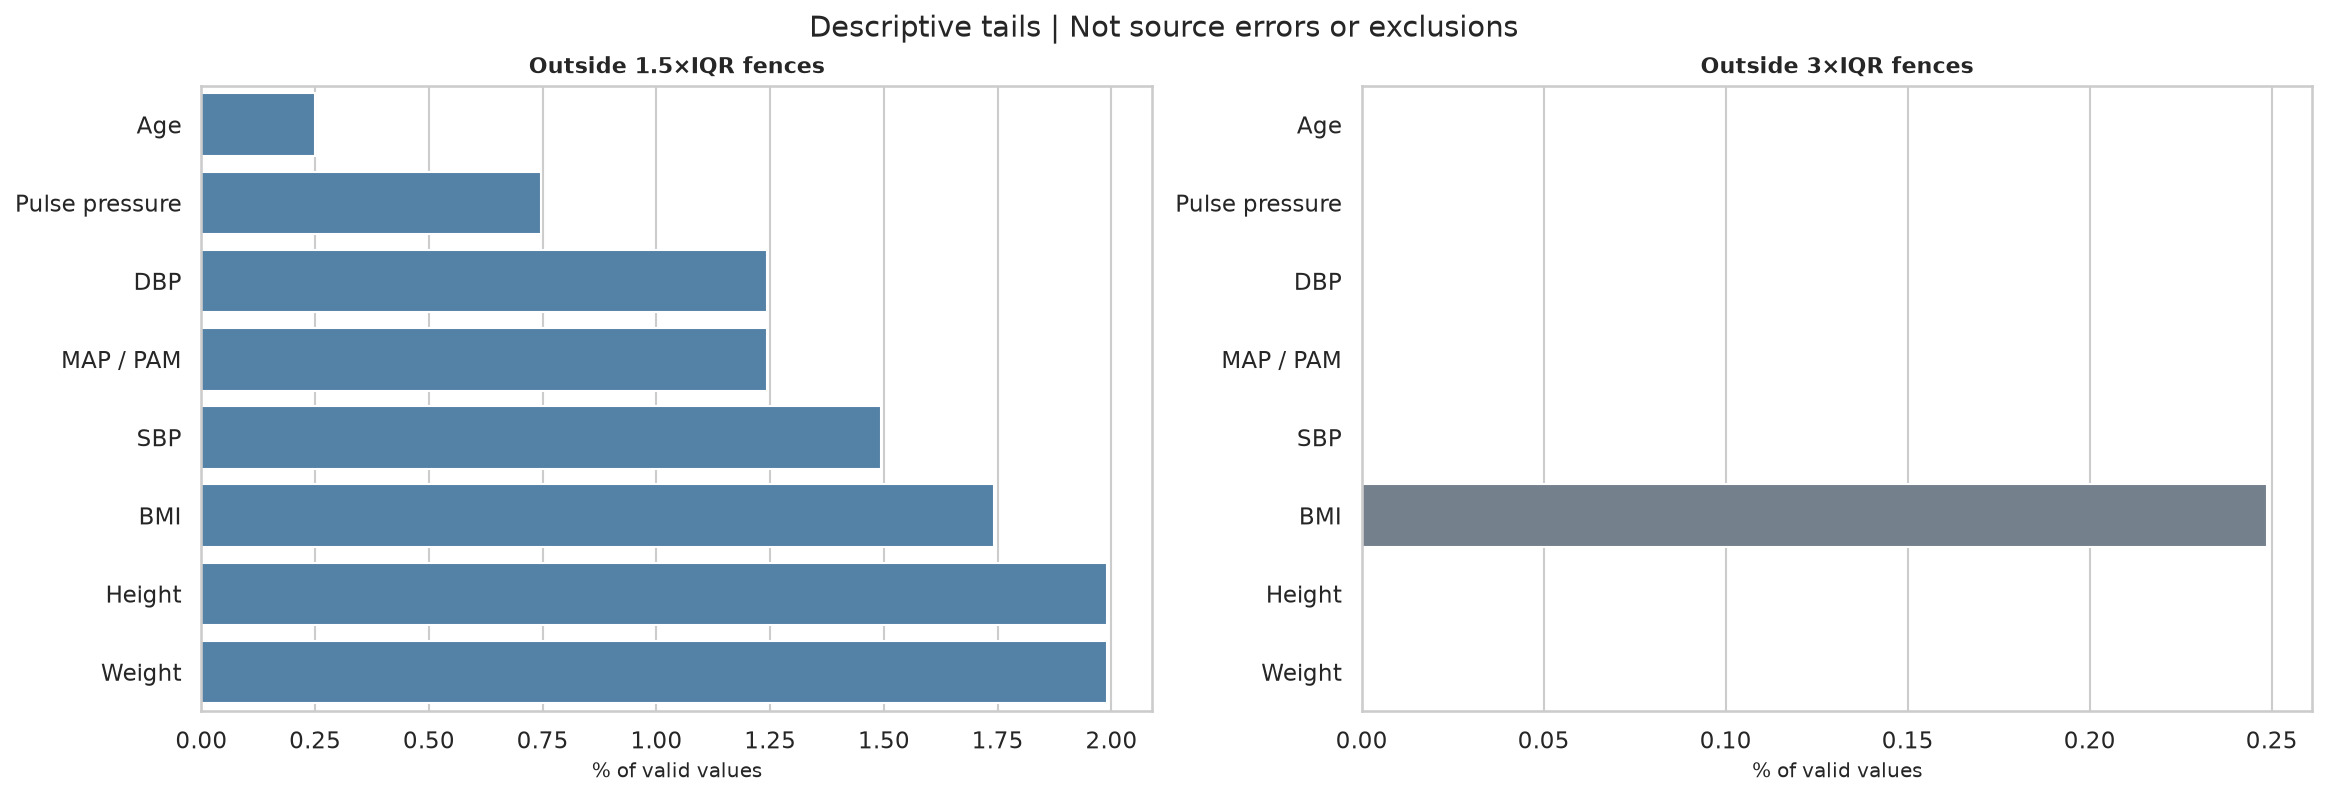

In [4]:
if MAKE_QQ_PANEL:
    fig, axes = plt.subplots(2, 4, figsize=(18.0, 8.6), constrained_layout=True)
    for ax, column in zip(axes.flat, ALL_COLS):
        values = source_df[column].dropna().to_numpy(dtype=float)
        if len(values) >= 3 and np.std(values) > 0:
            stats.probplot(values, dist='norm', plot=ax)
        else:
            ax.text(.5, .5, 'Insufficient variation', ha='center', va='center', transform=ax.transAxes)
        ax.set(title=label(column), xlabel='Theoretical quantiles', ylabel='Sample quantiles')
    fig.suptitle('Normal Q–Q views | Visual diagnostics only', fontsize=15)
    p = save_figure(fig, '03_non_hrv_qq_diagnostics.png', 'qq_multipanel',
                    'Eight Q–Q distribution diagnostics, no hypothesis tests')
    show_panel(p)

fig, axes = plt.subplots(1, 2, figsize=(15.4, 5.2), constrained_layout=True)
tail_sorted = tail_summary.sort_values('pct_outside_1_5_iqr')
sns.barplot(data=tail_sorted, x='pct_outside_1_5_iqr', y='label',
            color='steelblue', ax=axes[0])
axes[0].set(title='Outside 1.5×IQR fences', xlabel='% of valid values', ylabel='')
sns.barplot(data=tail_sorted, x='pct_outside_3_iqr', y='label',
            color='slategray', ax=axes[1])
axes[1].set(title='Outside 3×IQR fences', xlabel='% of valid values', ylabel='')
fig.suptitle('Descriptive tails | Not source errors or exclusions', fontsize=14)
p = save_figure(fig, '04_non_hrv_tukey_tails.png', 'iqr_tail_summary',
                'Percentages beyond Tukey sample fences at 1.5× and 3×IQR')
show_panel(p)

## 5. Relationships among continuous non-HRV variables

Spearman coefficients and joint observation counts are **descriptive summaries**. Mathematically related fields require special interpretation: BMI is computed from weight/height, MAP and PP from SBP/DBP, and height in meters is the same measurement as height in centimeters. These associations do **not** represent independent physiological findings. The figures show raw points (no regression or significance testing).

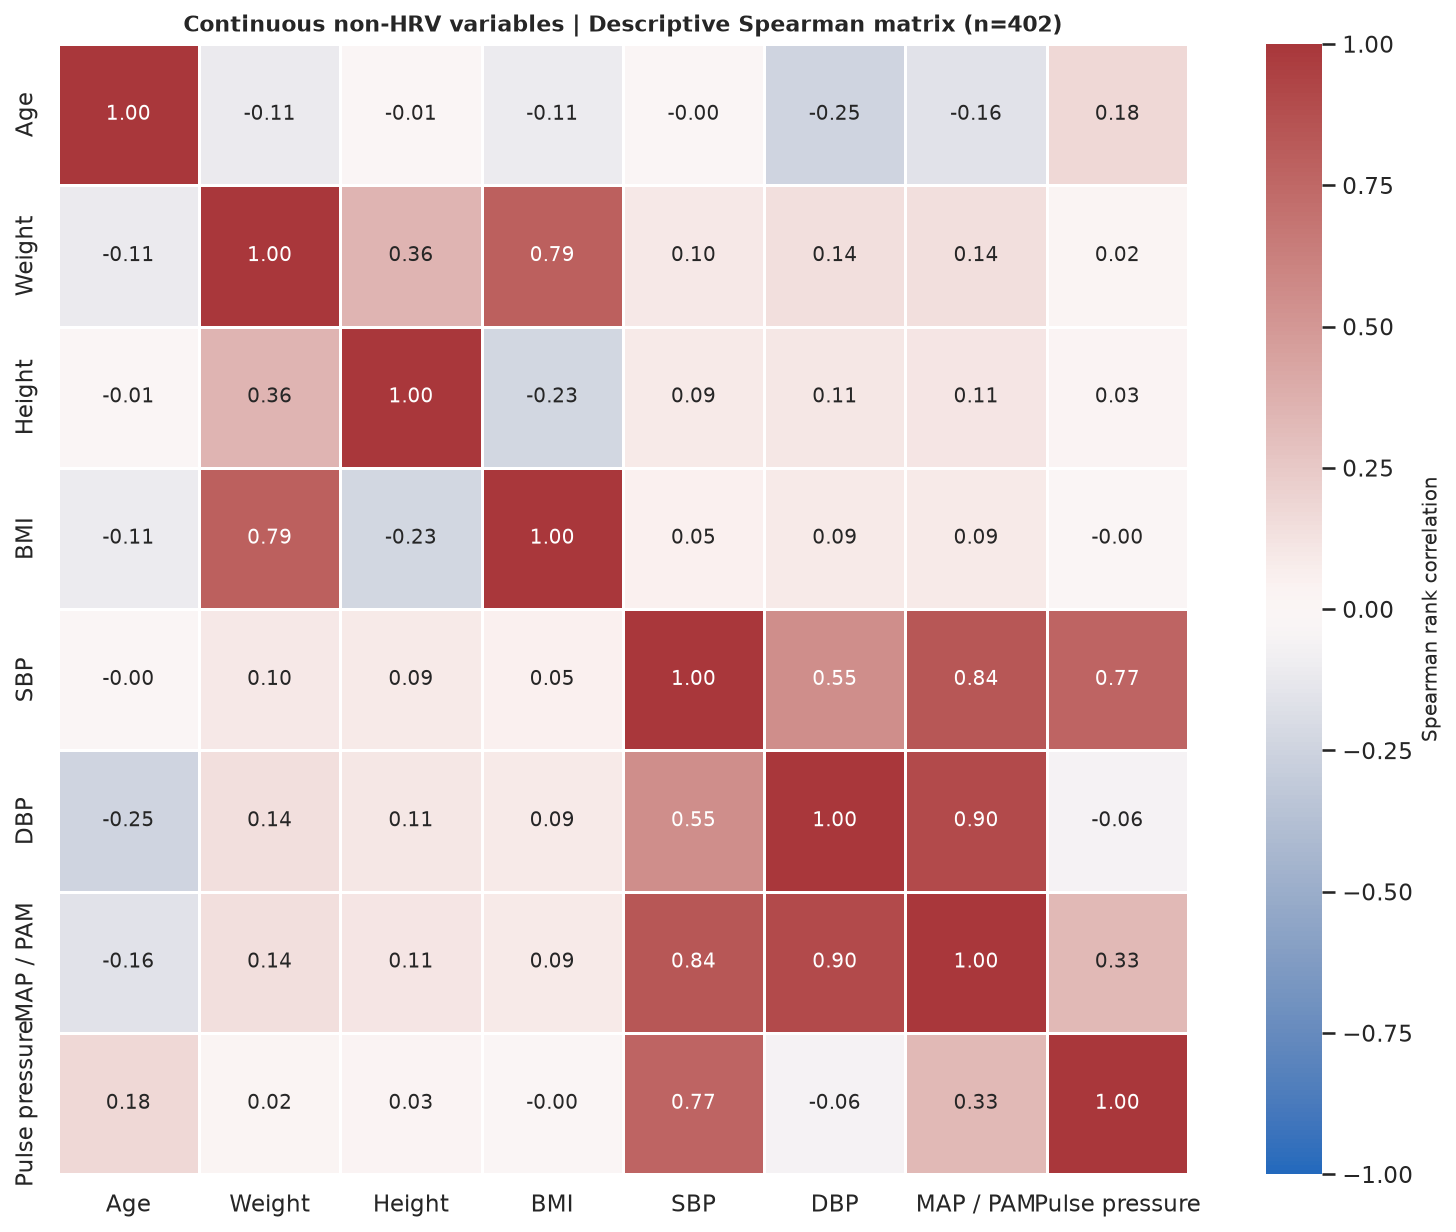

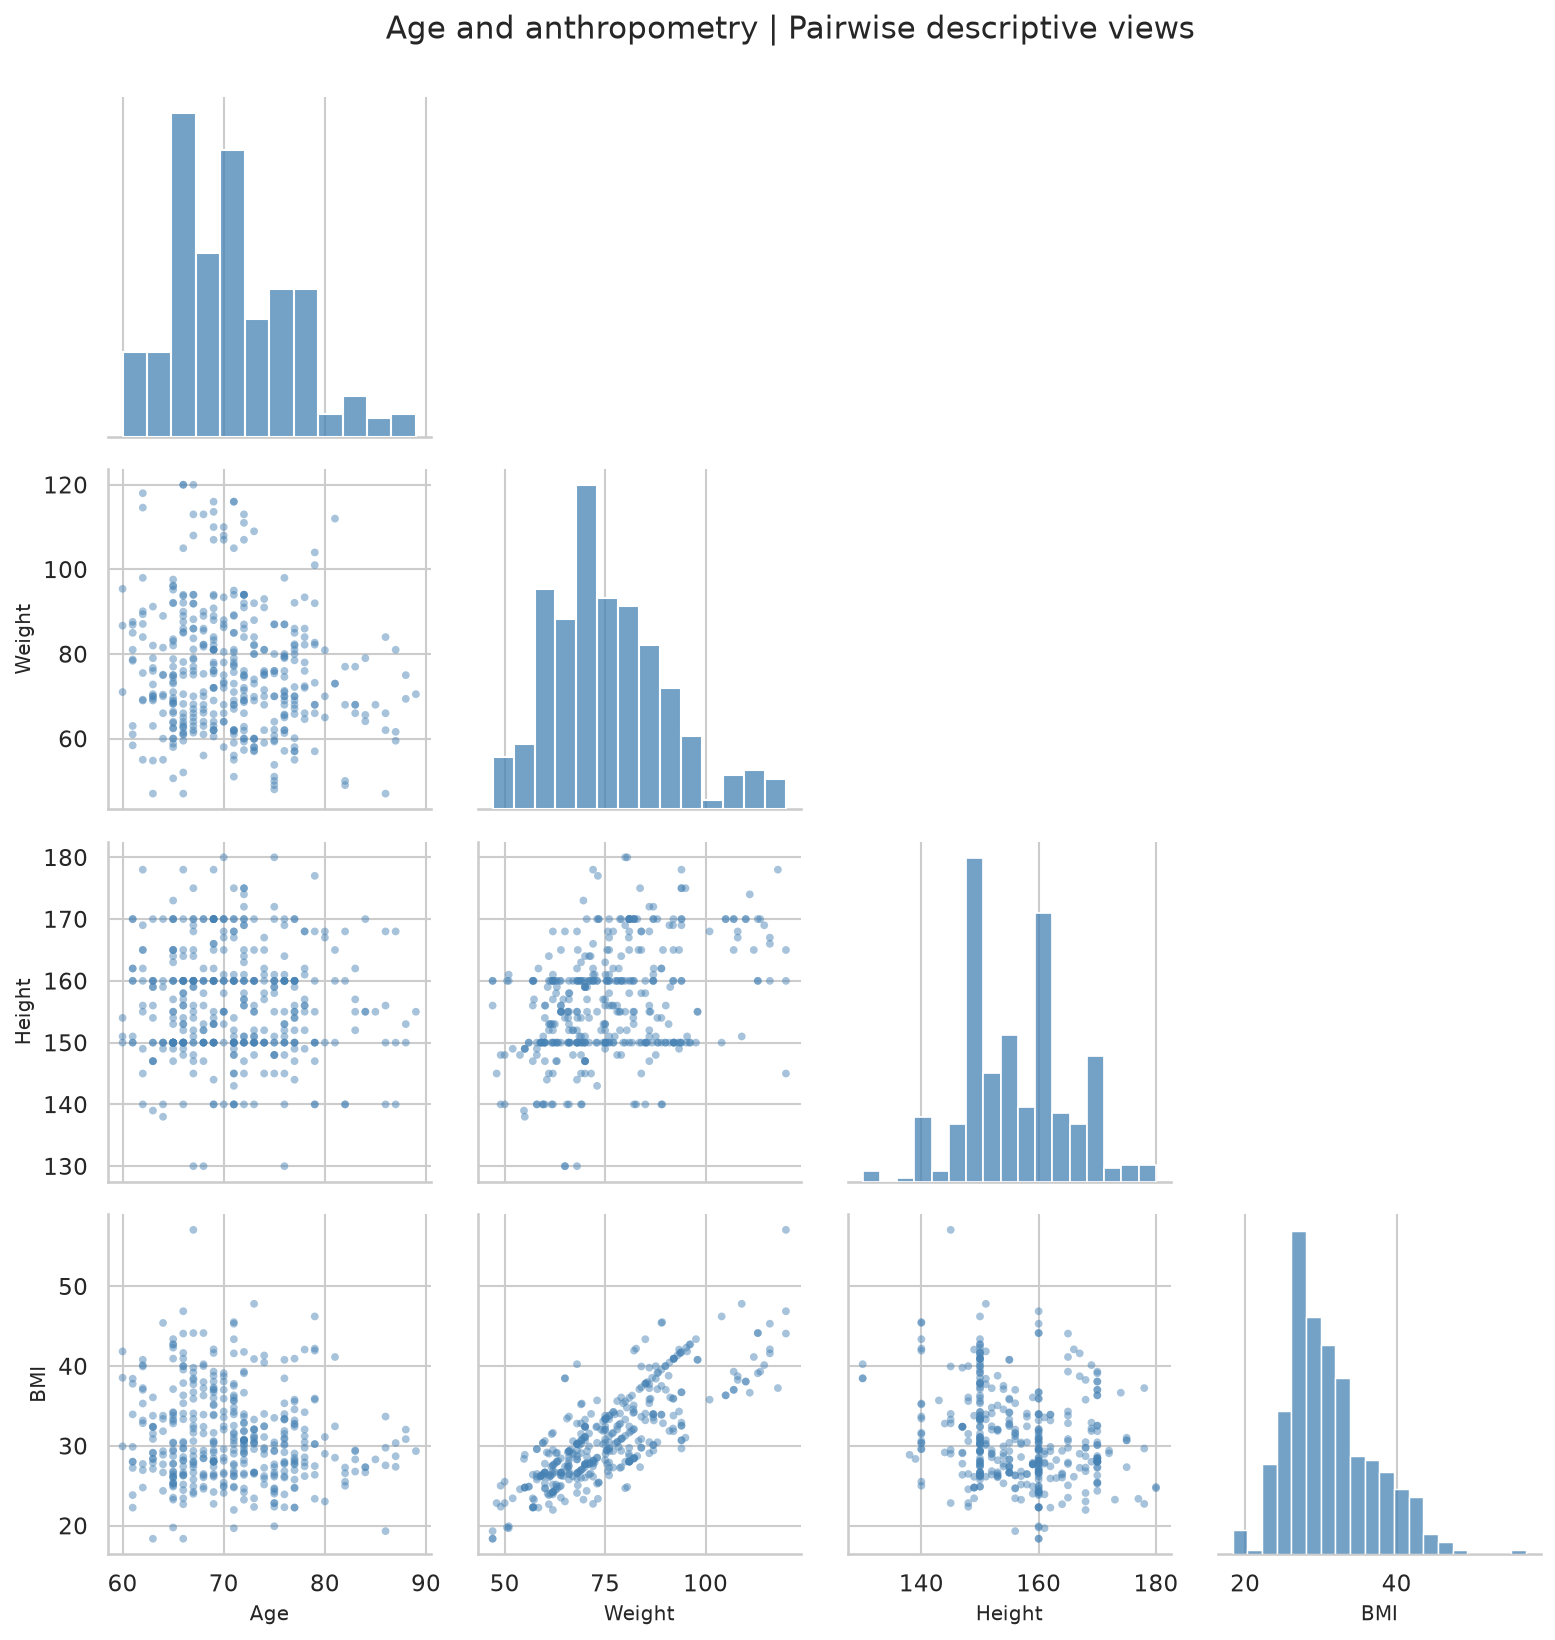

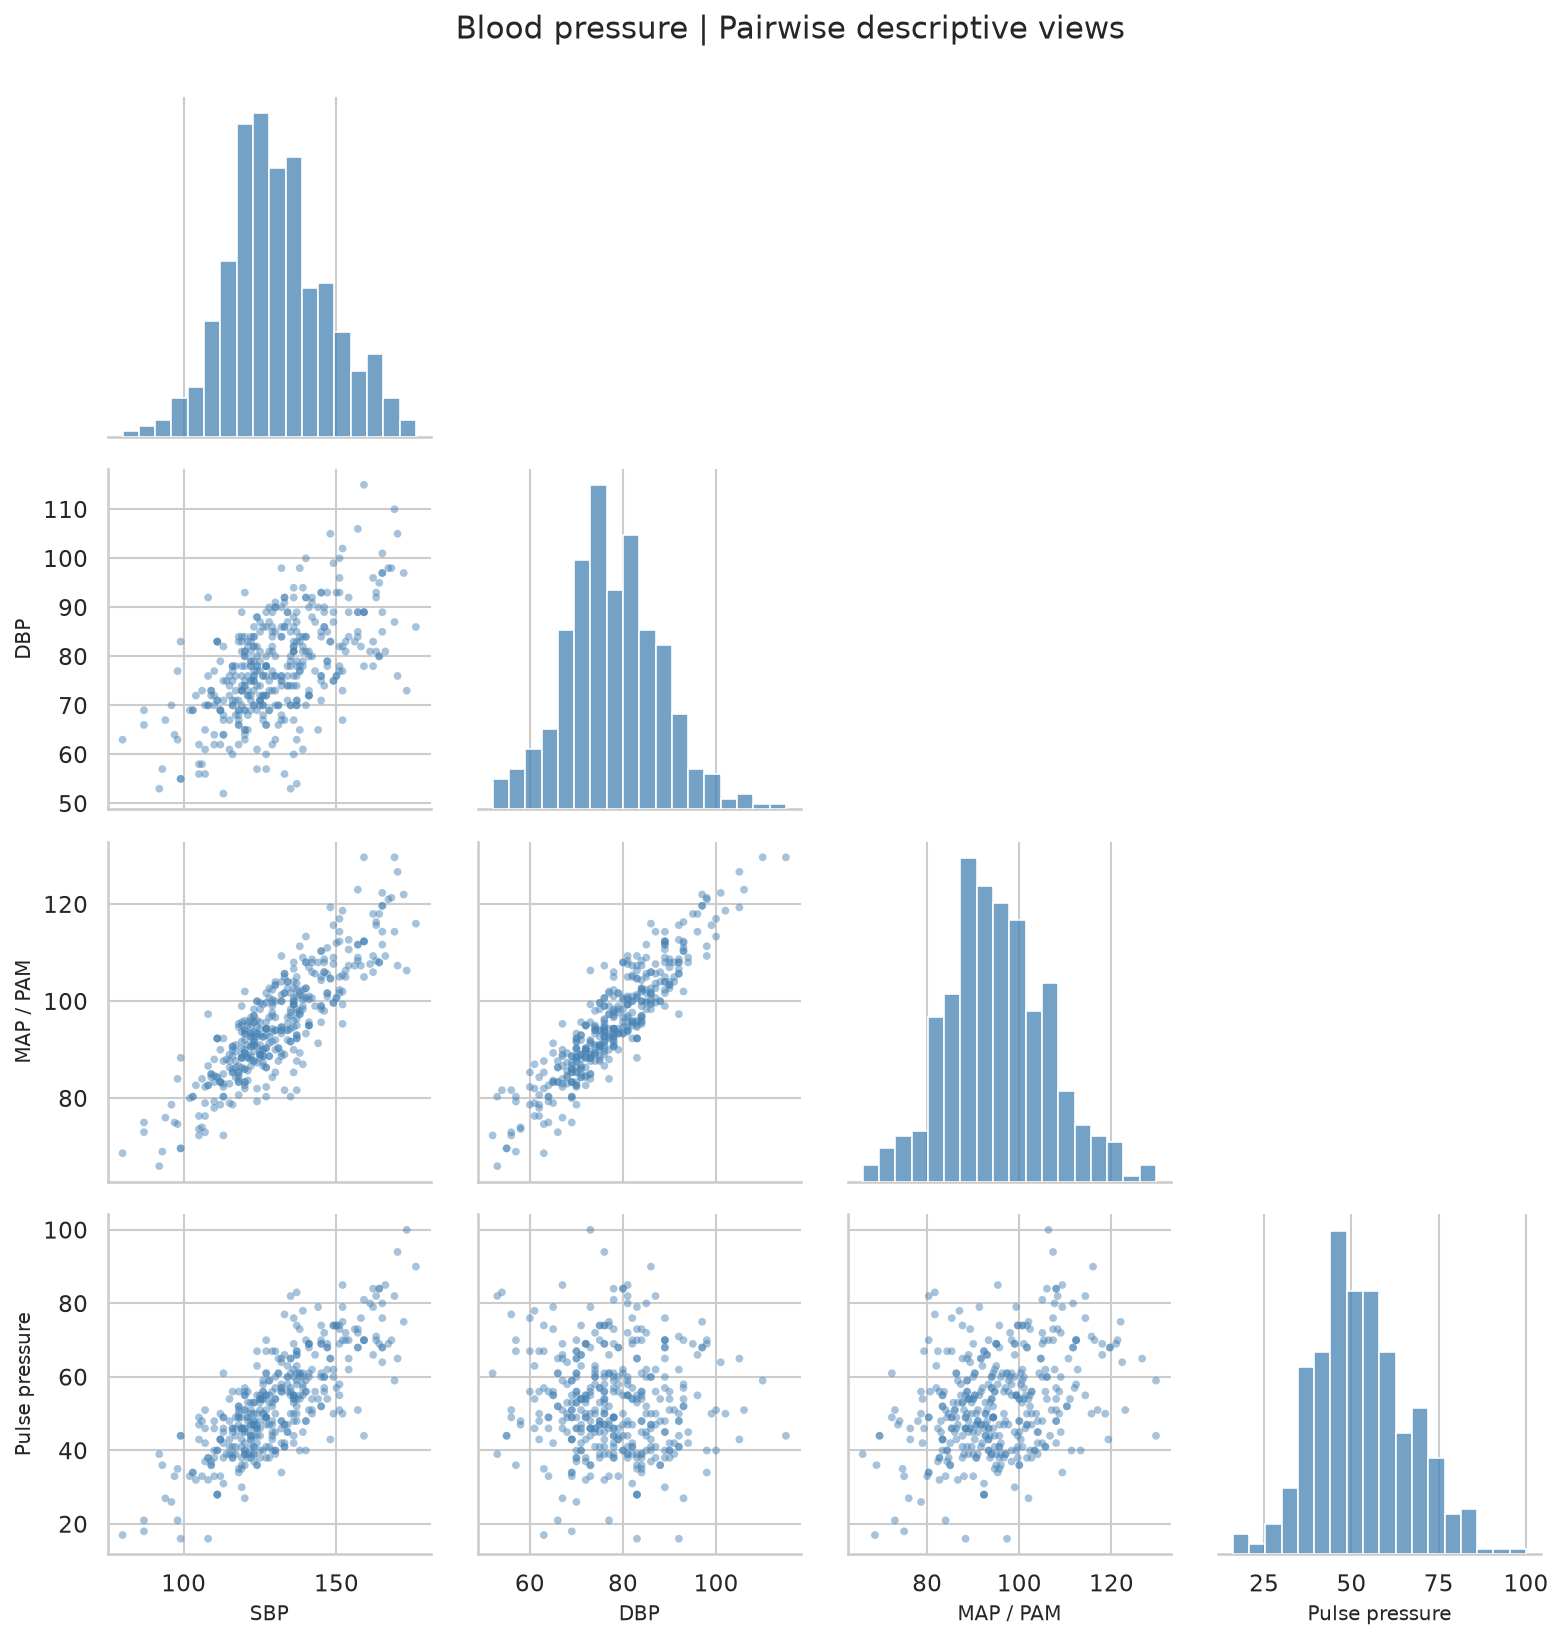

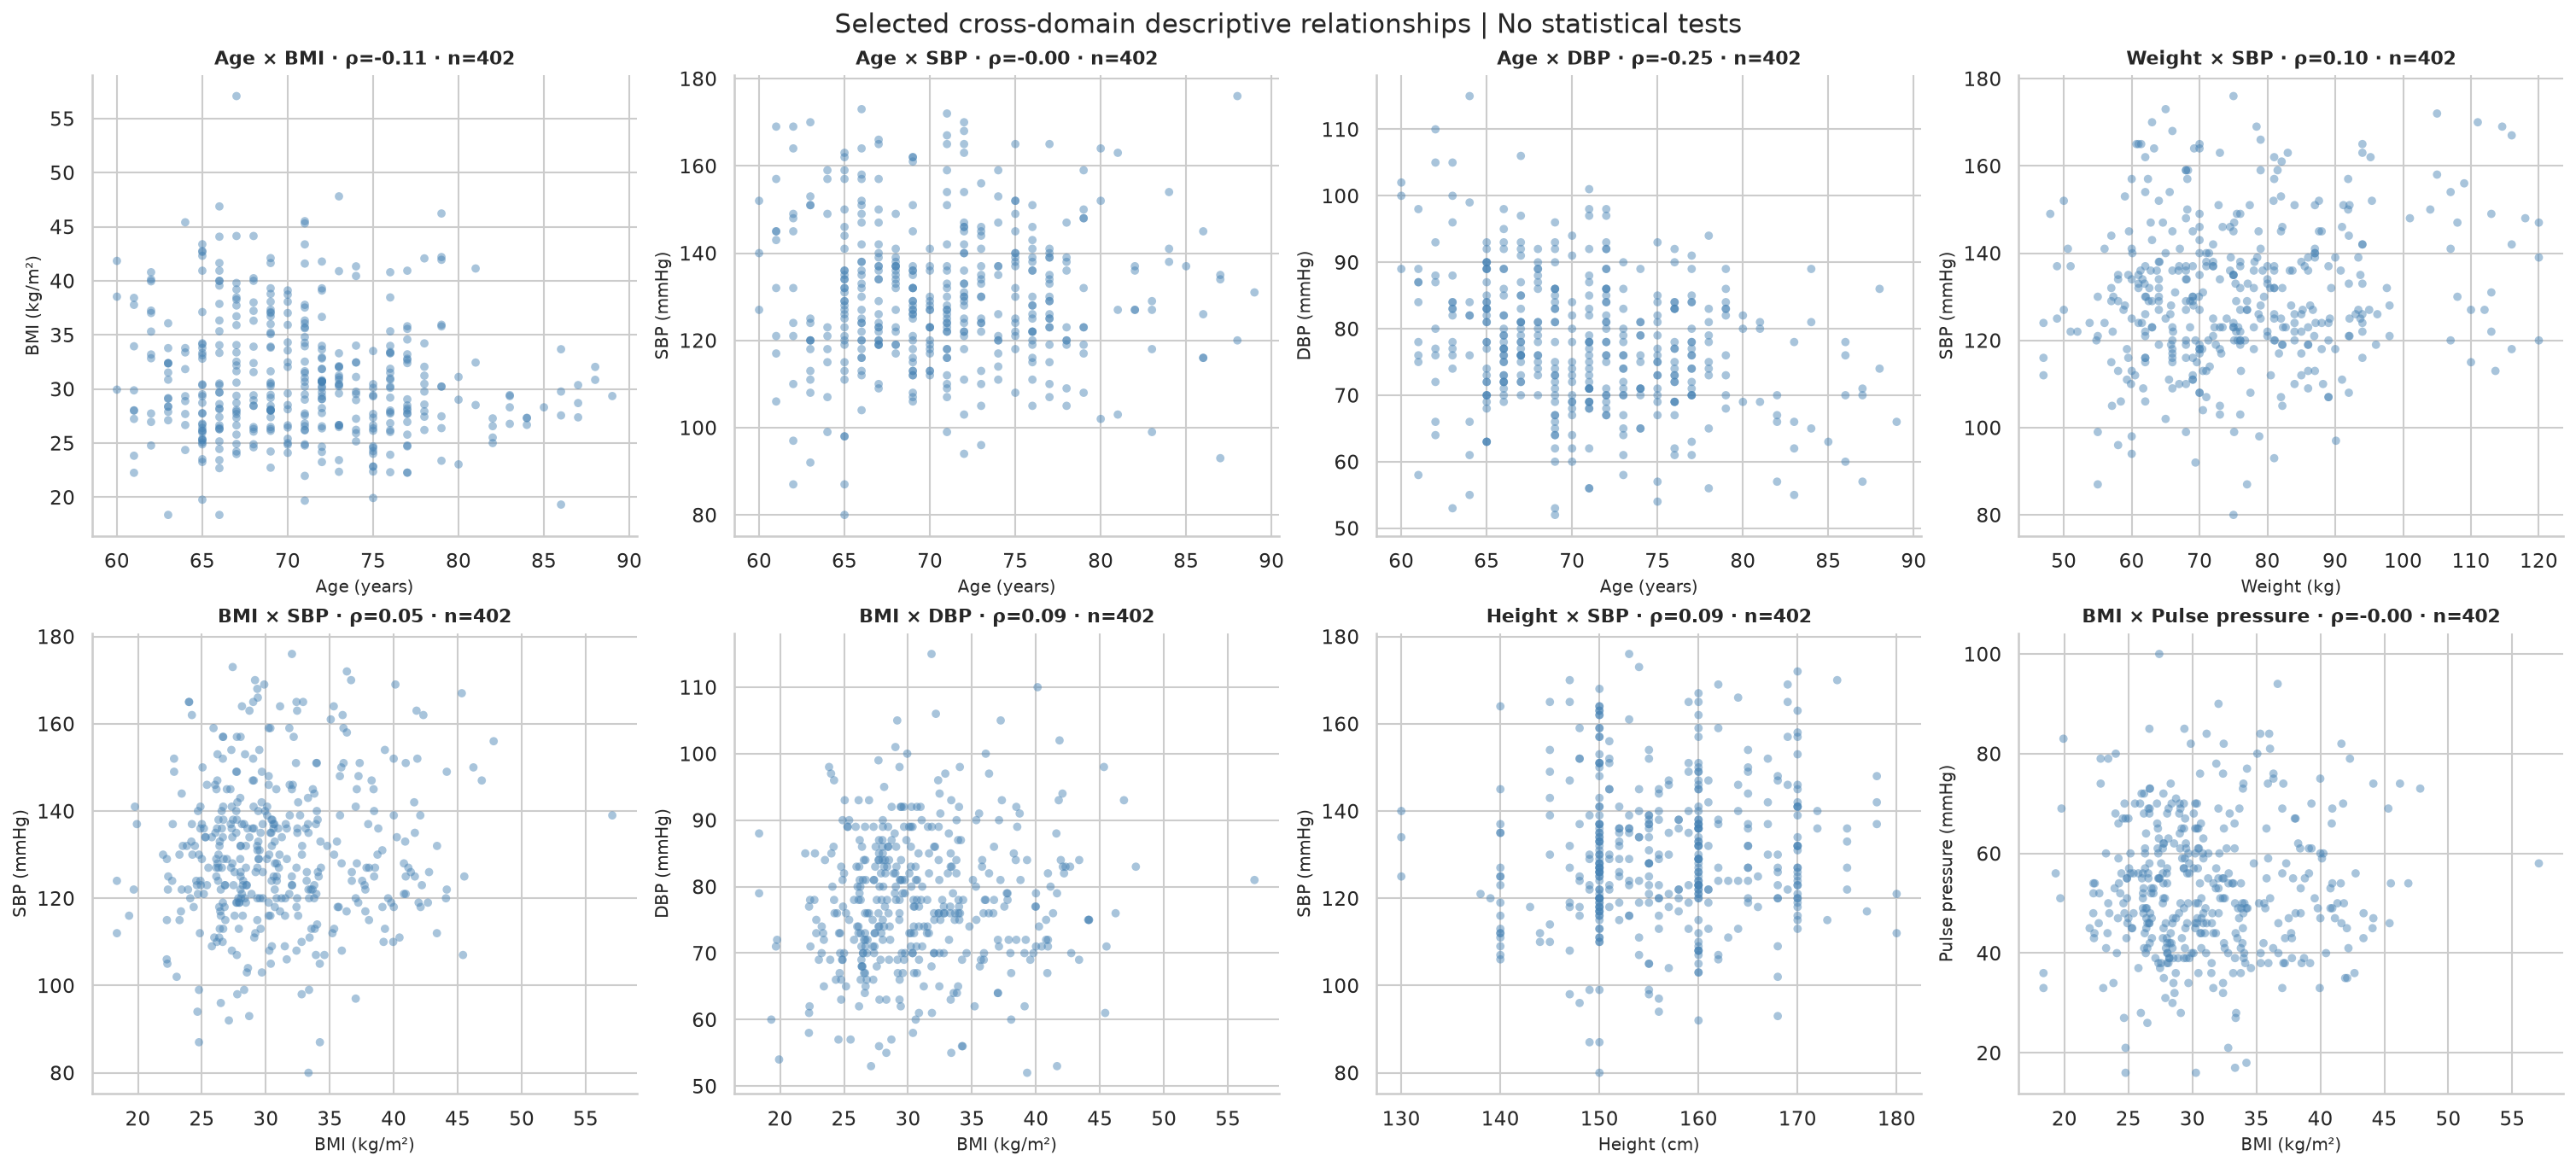

,variable_a,variable_b,n_pair,spearman_rho,abs_rho
25,bp_diastolic,bp_pam,402,0.904,0.904
23,bp_systolic,bp_pam,402,0.838,0.838
8,weight_kg,imc,402,0.789,0.789
24,bp_systolic,bp_pp,402,0.769,0.769
22,bp_systolic,bp_diastolic,402,0.548,0.548
7,weight_kg,height_cm,402,0.357,0.357
27,bp_pam,bp_pp,402,0.334,0.334
4,age,bp_diastolic,402,-0.246,0.246
13,height_cm,imc,402,-0.229,0.229
6,age,bp_pp,402,0.180,0.180


No inferential tests, regression models, HRV outcomes, or category comparisons were used.


In [5]:
pair_rows = []
for a, b in combinations(ALL_COLS, 2):
    pair = source_df[[a, b]].dropna()
    rho = (float(pair[a].corr(pair[b], method='spearman'))
           if len(pair) > 1 and pair[a].nunique() > 1 and pair[b].nunique() > 1
           else np.nan)
    pair_rows.append({'variable_a': a, 'variable_b': b,
                      'n_pair': len(pair), 'spearman_rho': rho})
pairs = pd.DataFrame(pair_rows)
pairs.to_csv(TABLES_DIR / 'non_hrv_spearman_pairs.csv', index=False)

rho_matrix = source_df[ALL_COLS].corr(method='spearman')
rho_matrix.to_csv(TABLES_DIR / 'non_hrv_spearman_matrix.csv', index=True)
pretty = rho_matrix.copy()
pretty.index = [label(c) for c in pretty.index]
pretty.columns = [label(c) for c in pretty.columns]
fig, ax = plt.subplots(figsize=(10.5, 8.1), constrained_layout=True)
sns.heatmap(pretty, cmap='vlag', vmin=-1, vmax=1, center=0,
            annot=True, fmt='.2f', square=True, linewidths=0.5,
            cbar_kws={'label': 'Spearman rank correlation'}, ax=ax)
ax.set(title=f'Continuous non-HRV variables | Descriptive Spearman matrix (n={N_RECORDS})')
p = save_figure(fig, '05_non_hrv_spearman_heatmap.png', 'spearman_heatmap',
                'Rank correlations across eight continuous non-HRV measurements')
show_panel(p, width=910)

if MAKE_PAIR_GRIDS:
    for columns, filename, heading in [
        (DEMO_ANTHRO_COLS, '06_age_anthropometry_pair_grid.png',
         'Age and anthropometry | Pairwise descriptive views'),
        (BP_COLS, '07_blood_pressure_pair_grid.png',
         'Blood pressure | Pairwise descriptive views'),
    ]:
        plot_data = source_df[columns].rename(columns={c: label(c) for c in columns})
        grid = sns.PairGrid(plot_data, corner=True, height=2.65, diag_sharey=False)
        grid.map_diag(sns.histplot, bins='auto', color='steelblue')
        grid.map_lower(sns.scatterplot, alpha=0.48, s=14,
                       edgecolor='none', color='steelblue')
        grid.figure.suptitle(heading, y=1.03, fontsize=15)
        p = save_figure(grid.figure, filename, 'pair_grid',
                        'Diagonal distributions plus all unique pairwise scatterplots')
        show_panel(p, width=920)

if MAKE_CROSS_DOMAIN_PANEL:
    selected = [
        ('age', 'imc'), ('age', 'bp_systolic'),
        ('age', 'bp_diastolic'), ('weight_kg', 'bp_systolic'),
        ('imc', 'bp_systolic'), ('imc', 'bp_diastolic'),
        ('height_cm', 'bp_systolic'), ('imc', 'bp_pp'),
    ]
    fig, axes = plt.subplots(2, 4, figsize=(20.0, 9.0), constrained_layout=True)
    for ax, (a, b) in zip(axes.flat, selected):
        pair = source_df[[a, b]].dropna()
        sns.scatterplot(data=pair, x=a, y=b, ax=ax, s=22, alpha=.47,
                        edgecolor='none', color='steelblue')
        rho = float(pair[a].corr(pair[b], method='spearman')) if len(pair) > 2 else np.nan
        rho_s = f'{rho:.2f}' if np.isfinite(rho) else 'NA'
        ax.set(title=f'{label(a)} × {label(b)} · ρ={rho_s} · n={len(pair)}',
               xlabel=axis_label(a), ylabel=axis_label(b))
        sns.despine(ax=ax)
    fig.suptitle('Selected cross-domain descriptive relationships | No statistical tests', fontsize=15)
    p = save_figure(fig, '08_age_anthropometry_pressure_cross_domain.png',
                    'cross_domain_scatter_grid',
                    'Eight age/anthropometry versus pressure relationships')
    show_panel(p)

display(pairs.assign(abs_rho=pairs.spearman_rho.abs())
        .sort_values('abs_rho', ascending=False).head(10).round(3))
print('No inferential tests, regression models, HRV outcomes, or category comparisons were used.')

## 6. Source representation notes and generated documentation

This stage checks that the alternative height unit and documented pressure derivatives are numerically consistent **without correcting anything**. It then writes the methodological README, descriptive results Markdown, and figure index. This is a data-inspection stage: observations that appear in plot tails remain part of the accepted cohort.

In [6]:
# Numeric representation checks only: no changed values and no new exclusion rules.
check_rows = []
for name, observed, expected, tolerance, detail in [
    ('height_m_vs_height_cm', source_df['height_m'], source_df['height_cm'] / 100,
     0.01, 'Height in meters versus centimeters / 100'),
    ('pulse_pressure_vs_sbp_minus_dbp', source_df['bp_pp'],
     source_df['bp_systolic'] - source_df['bp_diastolic'],
     0.01, 'Stored PP versus SBP − DBP'),
    ('map_vs_dbp_plus_one_third_pp', source_df['bp_pam'],
     source_df['bp_diastolic'] + (source_df['bp_systolic'] - source_df['bp_diastolic']) / 3,
     0.1, 'Stored MAP versus DBP + (SBP − DBP) / 3'),
]:
    delta = (observed - expected).abs()
    eligible = observed.notna() & expected.notna()
    check_rows.append({
        'check': name, 'description': detail, 'n_compared': int(eligible.sum()),
        'tolerance': tolerance,
        'max_abs_difference': float(delta[eligible].max()) if eligible.any() else np.nan,
        'n_above_tolerance': int((eligible & (delta > tolerance)).sum()),
        'action': 'documentation_only_no_changes',
    })
representation_checks = pd.DataFrame(check_rows)
representation_checks.to_csv(TABLES_DIR / 'non_hrv_representation_checks.csv', index=False)
display(representation_checks.round(5))

figure_manifest = pd.DataFrame(figure_records)
assert len(figure_manifest) in range(5, 9), f'Expected 5–8 multipanel figures, generated {len(figure_manifest)}.'
assert figure_manifest['figure'].is_unique
figure_manifest.to_csv(TABLES_DIR / 'figure_manifest.csv', index=False)


def format_value(value, decimals=2):
    if pd.isna(value):
        return 'NA'
    if isinstance(value, (int, np.integer)):
        return str(value)
    if isinstance(value, (float, np.floating)):
        return f'{value:.{decimals}f}'
    return str(value).replace('|', '\\|').replace('\n', ' ')


def markdown_table(frame, columns, decimals=2):
    header = '| ' + ' | '.join(columns) + ' |'
    separator = '| ' + ' | '.join(['---'] * len(columns)) + ' |'
    lines = [header, separator]
    for _, row in frame[columns].iterrows():
        lines.append('| ' + ' | '.join(format_value(row[c], decimals) for c in columns) + ' |')
    return '\n'.join(lines)

readme = f'''# Data inspection — 05.02 Non-HRV inspection

## Purpose and scope

This stage examines **continuous non-HRV variables**, not categorical groups or HRV outcomes. It is the second notebook in the three-part `data_inspection` stage:

1. `05_01_hrv_inspection.ipynb` — seven HRV and cardiac measures.
2. `05_02_non_hrv_inspection.ipynb` — age, anthropometry and continuous blood pressure (**this notebook**).
3. `05_03_category_counts.ipynb` — category distributions, marginal and joint counts (**separate future notebook**).

## Input and provenance

- Source: `outputs/dataset_final.csv` after preprocessing `01 → 01b → 02 → 03 → 04`.
- Records analyzed in this run: **{N_RECORDS}**, documented current release: {EXPECTED_N}.
- Unique source key: `{SOURCE_COLUMN}`.
- Source file SHA-256: `{INPUT_SHA256}`.
- Main continuous measures: {', '.join('`' + c + '`' for c in ALL_COLS)}.
- `height_m` is summarized and checked but not separately plotted because it reproduces the same height as `height_cm` in a different unit.
- `sex` and all `_category`, `_group`, and `_reference` factors are **reserved for 05.03**, with no frequency or subgroup analyses here.

## Methods

- Descriptive univariate summaries: completeness, central tendency, percentiles P01–P99, spread, sample skewness and excess kurtosis, and CV when the mean is nonzero.
- Tukey 1.5×IQR and 3×IQR fences: **descriptive tail counts only**, not error diagnosis, exclusion or clinical classification.
- Two original-scale multipanel distribution sheets (age/anthropometry and pressure): histogram + KDE, violin/quartiles, and ECDF.
- Optional consolidated Q–Q sheet, one IQR-tail summary sheet, Spearman correlation heatmap, two within-domain pair grids, and one selected cross-domain scatter sheet.
- Spearman coefficients describe rank association; **no p-values, models, hypothesis tests or clinical thresholds** are used.
- Algebraically linked variables are not independent: BMI relates weight and height; MAP and PP relate SBP and DBP. These dependencies are recorded as context for later factor analyses.
- One source-representation table documents differences in height units, PP and MAP computations; **no recomputation of inputs and no changes to source values**.
- All plots use original measurement scales; none is automatically log-transformed or standardized.

## Output contract

Root: `eda_results/data_inspection/05_02_non_hrv_inspection/`

- `tables/non_hrv_descriptive_statistics.csv`
- `tables/height_m_alternative_summary.csv`
- `tables/non_hrv_tukey_tail_summary.csv`
- `tables/non_hrv_spearman_pairs.csv`
- `tables/non_hrv_spearman_matrix.csv`
- `tables/non_hrv_representation_checks.csv`
- `tables/figure_manifest.csv`
- `figures/multipanels/` — **{len(figure_manifest)} consolidated figures**
- `README_05_non_hrv_inspection.md` — generated methodological record
- `05_non_hrv_inspection_results.md` — generated descriptive result record

Old generated PNG files are removed **only when listed** in the prior `figure_manifest.csv` and only inside the multipanel directory; unrelated files are not changed.

## Interpretation safeguards

Descriptive shapes, tail observations, ranks and differences in scale do not prove source errors. No participant is removed. No claim is made about HRV relationships, gender differences, age-group patterns or category frequencies. Those questions belong to other notebooks. The observational sample is not interpreted causally.

## Execution and dependencies

Run in the project tree so that `outputs/dataset_final.csv` is discoverable, or set `INPUT_FILE_OVERRIDE` in the configuration cell. Dependencies: Python, pandas, NumPy, matplotlib, seaborn, scipy and Jupyter/IPython.

- Python: {platform.python_version()}
- pandas: {pd.__version__}
- numpy: {np.__version__}
- matplotlib: {matplotlib.__version__}
- seaborn: {sns.__version__}
- scipy: {__import__('scipy').__version__}
'''

brief = summary[['label','unit','n_valid','n_missing','mean','median','std','q25','q75','p95','skewness','n_outside_1_5_iqr']]
ranked_skew = summary[['label','skewness']].sort_values('skewness', ascending=False)
ranked_tail = summary[['label','n_outside_1_5_iqr','pct_outside_1_5_iqr']].sort_values('pct_outside_1_5_iqr', ascending=False)
ranked_pairs = pairs.dropna(subset=['spearman_rho']).copy()
ranked_pairs['abs_rho'] = ranked_pairs['spearman_rho'].abs()
ranked_pairs = ranked_pairs.sort_values('abs_rho', ascending=False).head(10)
ranked_pairs['measure_a'] = ranked_pairs['variable_a'].map(label)
ranked_pairs['measure_b'] = ranked_pairs['variable_b'].map(label)

results_md = f'''# 05.02 Non-HRV inspection — Descriptive results

**Input:** `{INPUT_FILE.name}` · **Analyzed records:** {N_RECORDS} · **Plotted continuous measures:** {len(ALL_COLS)}  
**Scope:** age, anthropometry and blood-pressure distributions; descriptive relationships within/between these domains. **No HRV, category counts, subgroup comparisons or inference.**

## 1. Completeness and descriptive summary

{markdown_table(brief, list(brief.columns))}

The height-in-meters field is an alternate unit of the same measurement, summarized independently in `tables/height_m_alternative_summary.csv`, and deliberately not counted as another independent variable in the figures.

## 2. Distribution shapes and descriptive tail observations

Skewness (descending):

{markdown_table(ranked_skew, ['label','skewness'])}

Sample observations outside Tukey 1.5×IQR fences (not a QC error label):

{markdown_table(ranked_tail, ['label','n_outside_1_5_iqr','pct_outside_1_5_iqr'])}

The 3×IQR tail summary and fences are saved in `tables/non_hrv_tukey_tail_summary.csv`. The plotted data remain in original units and no values were removed or corrected.

## 3. Descriptive relationships

Largest absolute Spearman coefficients among the 28 pairs:

{markdown_table(ranked_pairs[['measure_a','measure_b','n_pair','spearman_rho']], ['measure_a','measure_b','n_pair','spearman_rho'], 3)}

**Important:** Associations involving BMI and weight/height, or MAP/PP and SBP/DBP, partly reflect mathematical definitions. They do not constitute independent observations about causal physiology.

## 4. Source representation checks (documentation only)

{markdown_table(representation_checks, list(representation_checks.columns), 5)}

The checks do not re-clean, modify, flag for removal, or exclude any record; differences above the stated arithmetic tolerances are simply documented if observed.

## 5. Figure index

{markdown_table(figure_manifest[['figure','description']], ['figure','description'])}

## 6. Closing notes

- This stage used **{N_RECORDS} source records** without modification or exclusion.
- Produced **{len(figure_manifest)} multipanel descriptive figures** and numerical summaries.
- No categorical counts or proportions are generated. Those belong to notebook **05.03**.
- No HRV association claims, subgroup comparisons, hypothesis testing or models are included.
'''

(OUTPUT_DIR / 'README_05_non_hrv_inspection.md').write_text(readme, encoding='utf-8')
(OUTPUT_DIR / '05_non_hrv_inspection_results.md').write_text(results_md, encoding='utf-8')

assert summary.shape[0] == len(ALL_COLS)
assert len(pairs) == len(ALL_COLS) * (len(ALL_COLS) - 1) // 2
assert source_df[SOURCE_COLUMN].is_unique
assert len(source_df) == N_RECORDS
print(f'Completed: n={N_RECORDS}; continuous variables={len(ALL_COLS)}; pairs={len(pairs)}; multipanels={len(figure_manifest)}')
print('README:', OUTPUT_DIR / 'README_05_non_hrv_inspection.md')
print('Results:', OUTPUT_DIR / '05_non_hrv_inspection_results.md')
print('No HRV analysis, category counts, modeling, input modifications, or exclusions performed.')

,check,description,n_compared,tolerance,max_abs_difference,n_above_tolerance,action
0,height_m_vs_height_cm,Height in meters versus centimeters / 100,402,0.01,0.0,0,documentation_only_no_changes
1,pulse_pressure_vs_sbp_minus_dbp,Stored PP versus SBP − DBP,402,0.01,0.0,0,documentation_only_no_changes
2,map_vs_dbp_plus_one_third_pp,Stored MAP versus DBP + (SBP − DBP) / 3,402,0.10,0.0,0,documentation_only_no_changes


Completed: n=402; continuous variables=8; pairs=28; multipanels=8
README: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/eda_results/data_inspection/05_02_non_hrv_inspection/README_05_non_hrv_inspection.md
Results: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/eda_results/data_inspection/05_02_non_hrv_inspection/05_non_hrv_inspection_results.md
No HRV analysis, category counts, modeling, input modifications, or exclusions performed.
